<a href="https://colab.research.google.com/github/johnsimon3110-star/STUDENT-EXAMINATION-SCORE-PREDICTION-USING-LINEAR-REGRESSION/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

# ==========================================================
# STAGE 1 — IMPORT LIBRARIES AND LOAD DATASET
# Purpose: Import the required Python libraries and upload
# the Student Performance Factors CSV dataset.
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from io import BytesIO

print("Please upload your Student Performance Factors CSV file.")

uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))

df = pd.read_csv(BytesIO(uploaded[file_name]))

print("\nDATASET LOADED SUCCESSFULLY")
print("===========================")
print("File name:", file_name)
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])


Please upload your Student Performance Factors CSV file.


Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (1).csv

DATASET LOADED SUCCESSFULLY
File name: StudentPerformanceFactors (1).csv
Total records: 6607
Total columns: 20


In [5]:

# ==========================================================
# STAGE 2 — DATASET INSPECTION
# Purpose: Examine the first records, column names, data
# types and general structure of the dataset.
# ==========================================================

# Display the first five records
print("FIRST FIVE RECORDS")
print("==================")
display(df.head())

# Display all column names
print("\nDATASET COLUMN NAMES")
print("====================")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION")
print("===================")
df.info()

# Display statistical summary
print("\nSTATISTICAL SUMMARY")
print("===================")
display(df.describe(include="all"))


FIRST FIVE RECORDS


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



DATASET COLUMN NAMES
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previ

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
count,6607.000000,6607.000000,6607,6607,6607,6607.00000,6607.000000,6607,6607,6607.000000,6607,6529,6607,6607,6607.000000,6607,6517,6540,6607,6607.000000
unique,NaN,NaN,3,3,2,NaN,NaN,3,2,NaN,3,3,2,3,NaN,2,3,3,2,NaN
top,NaN,NaN,Medium,Medium,Yes,NaN,NaN,Medium,Yes,NaN,Low,Medium,Public,Positive,NaN,No,High School,Near,Male,NaN
freq,NaN,NaN,3362,3319,3938,NaN,NaN,3351,6108,NaN,2672,3925,4598,2638,NaN,5912,3223,3884,3814,NaN
mean,19.975329,79.977448,NaN,NaN,NaN,7.02906,75.070531,NaN,NaN,1.493719,NaN,NaN,NaN,NaN,2.967610,NaN,NaN,NaN,NaN,67.235659
std,5.990594,11.547475,NaN,NaN,NaN,1.46812,14.399784,NaN,NaN,1.230570,NaN,NaN,NaN,NaN,1.031231,NaN,NaN,NaN,NaN,3.890456
min,1.000000,60.000000,NaN,NaN,NaN,4.00000,50.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,55.000000
25%,16.000000,70.000000,NaN,NaN,NaN,6.00000,63.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,65.000000
50%,20.000000,80.000000,NaN,NaN,NaN,7.00000,75.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,67.000000
75%,24.000000,90.000000,NaN,NaN,NaN,8.00000,88.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,69.000000


In [6]:

# ==========================================================
# STAGE 3 — DATA QUALITY ASSESSMENT
# Purpose: Identify missing values, duplicate records,
# and unusual values in the dataset.
# ==========================================================

# 1. Check missing values
print("MISSING VALUES")
print("================")

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

# 2. Check duplicate records
print("\nDUPLICATE RECORDS")
print("=================")

print("Number of duplicates:", df.duplicated().sum())

# 3. Check examination score range
print("\nEXAMINATION SCORE CHECK")
print("=======================")

print("Minimum score:", df["Exam_Score"].min())
print("Maximum score:", df["Exam_Score"].max())

# 4. Identify scores above 100
print("\nSCORES ABOVE 100")
print("================")

print(df[df["Exam_Score"] > 100][["Exam_Score"]])


MISSING VALUES
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Total missing values: 235

DUPLICATE RECORDS
Number of duplicates: 0

EXAMINATION SCORE CHECK
Minimum score: 55
Maximum score: 101

SCORES ABOVE 100
      Exam_Score
1525         101


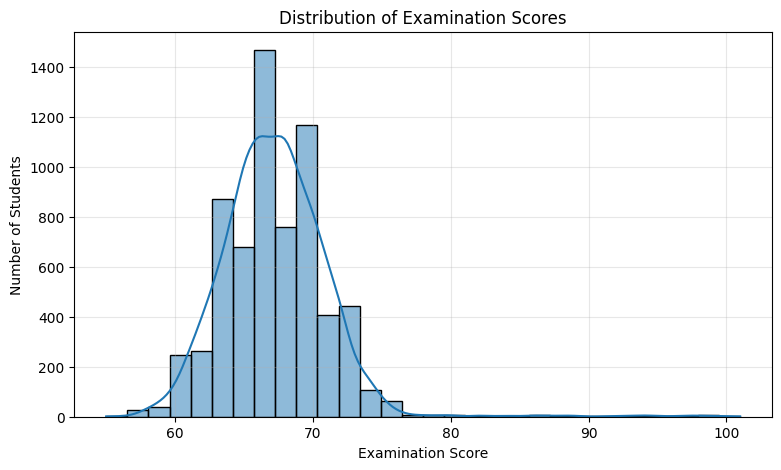

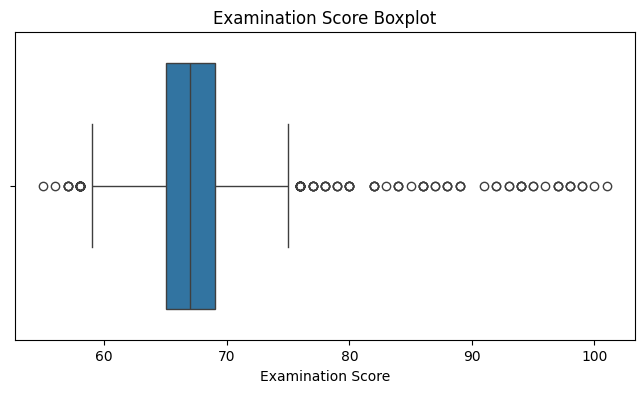

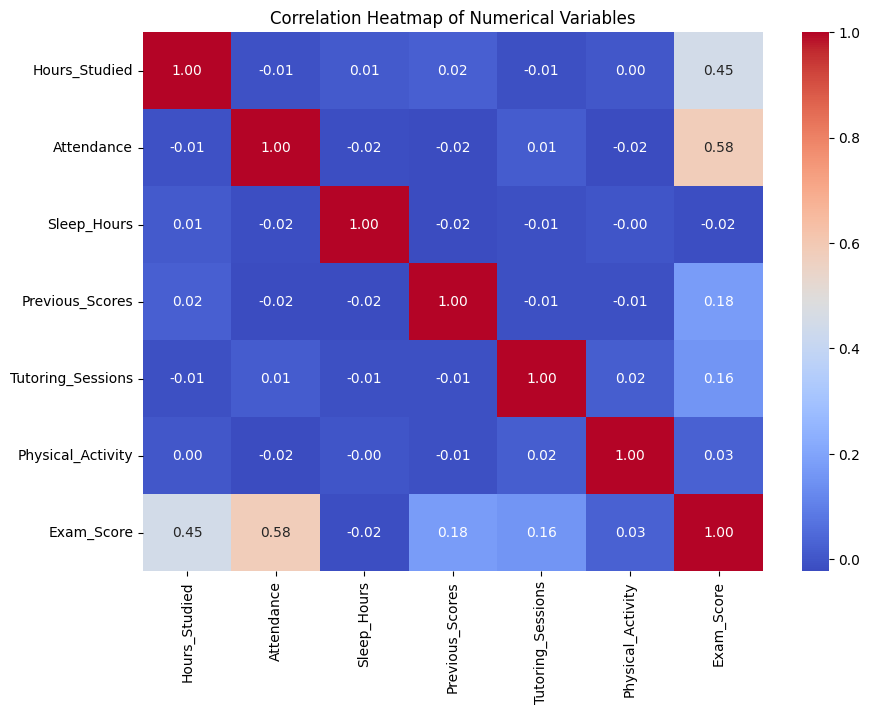

In [7]:

# ==========================================================
# STAGE 4 — EXPLORATORY DATA ANALYSIS (EDA)
# Purpose: Visualize examination score distribution and
# investigate relationships among numerical variables.
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Examination score distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    df["Exam_Score"],
    bins=30,
    kde=True
)

plt.title("Distribution of Examination Scores")
plt.xlabel("Examination Score")
plt.ylabel("Number of Students")
plt.grid(alpha=0.3)
plt.show()

# 2. Boxplot to inspect unusual examination scores
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["Exam_Score"])

plt.title("Examination Score Boxplot")
plt.xlabel("Examination Score")
plt.show()

# 3. Correlation heatmap
numerical_data = df.select_dtypes(include=["number"])

plt.figure(figsize=(10, 7))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


In [8]:

# ==========================================================
# STAGE 5 — CATEGORICAL FACTOR ANALYSIS
# Purpose: Compare average examination scores across the
# categories of each categorical independent variable.
# ==========================================================

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in categorical_columns:

    summary = df.groupby(
        column, dropna=False
    )["Exam_Score"].mean().sort_values(
        ascending=False
    )

    print("\n" + "=" * 50)
    print("FACTOR:", column)
    print("=" * 50)

    print(summary.round(2))



FACTOR: Parental_Involvement
Parental_Involvement
High      68.09
Medium    67.10
Low       66.36
Name: Exam_Score, dtype: float64

FACTOR: Access_to_Resources
Access_to_Resources
High      68.09
Medium    67.13
Low       66.20
Name: Exam_Score, dtype: float64

FACTOR: Extracurricular_Activities
Extracurricular_Activities
Yes    67.44
No     66.93
Name: Exam_Score, dtype: float64

FACTOR: Motivation_Level
Motivation_Level
High      67.70
Medium    67.33
Low       66.75
Name: Exam_Score, dtype: float64

FACTOR: Internet_Access
Internet_Access
Yes    67.29
No     66.54
Name: Exam_Score, dtype: float64

FACTOR: Family_Income
Family_Income
High      67.84
Medium    67.33
Low       66.85
Name: Exam_Score, dtype: float64

FACTOR: Teacher_Quality
Teacher_Quality
High      67.68
Medium    67.11
Low       66.75
NaN       66.64
Name: Exam_Score, dtype: float64

FACTOR: School_Type
School_Type
Private    67.29
Public     67.21
Name: Exam_Score, dtype: float64

FACTOR: Peer_Influence
Peer_Influen

In [9]:

# ==========================================================
# STAGE 6 — OUTLIER INVESTIGATION
# Purpose: Examine unusual examination scores using the
# Interquartile Range (IQR) statistical method.
# We will investigate, not automatically delete, outliers.
# ==========================================================

# Calculate quartiles
Q1 = df["Exam_Score"].quantile(0.25)
Q3 = df["Exam_Score"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate lower and upper boundaries
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df[
    (df["Exam_Score"] < lower_limit) |
    (df["Exam_Score"] > upper_limit)
]

print("OUTLIER INVESTIGATION")
print("====================")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_limit)
print("Upper boundary:", upper_limit)

print("\nNumber of potential outliers:", len(outliers))

print("\nOUTLIER RECORDS:")
display(outliers[["Hours_Studied", "Attendance", "Exam_Score"]])

print("\nHighest examination scores:")
display(
    df.nlargest(10, "Exam_Score")[
        ["Hours_Studied", "Attendance", "Exam_Score"]
    ]
)


OUTLIER INVESTIGATION
Q1: 65.0
Q3: 69.0
IQR: 4.0
Lower boundary: 59.0
Upper boundary: 75.0

Number of potential outliers: 104

OUTLIER RECORDS:


,Hours_Studied,Attendance,Exam_Score
94,18,89,100
106,31,100,76
113,35,99,79
209,43,86,78
217,19,70,89
...,...,...,...
6347,28,96,98
6393,16,83,98
6431,4,60,58
6522,18,90,95



Highest examination scores:


,Hours_Studied,Attendance,Exam_Score
1525,27,98,101
94,18,89,100
2425,23,83,99
3579,14,90,99
4192,28,90,98
6347,28,96,98
6393,16,83,98
529,15,83,97
919,21,74,97
5966,25,99,97


In [10]:

# ==========================================================
# STAGE 7 — FEATURE SELECTION
# Purpose: Define independent variables (X) and the target
# variable (Y) for our two regression models.
# ==========================================================

# Target variable
y = df["Exam_Score"]

# MODEL A: Two selected independent variables
X_A = df[["Attendance", "Hours_Studied"]]

# MODEL B: All independent variables
X_B = df.drop(columns=["Exam_Score"])

# Display the selected features
print("MODEL A — TWO INDEPENDENT VARIABLES")
print("===================================")
print(X_A.columns.tolist())

print("\nMODEL B — ALL INDEPENDENT VARIABLES")
print("===================================")
print(X_B.columns.tolist())

print("\nTARGET VARIABLE")
print("================")
print("Exam_Score")

print("\nDATASET SHAPES")
print("==============")
print("Model A:", X_A.shape)
print("Model B:", X_B.shape)
print("Target:", y.shape)


MODEL A — TWO INDEPENDENT VARIABLES
['Attendance', 'Hours_Studied']

MODEL B — ALL INDEPENDENT VARIABLES
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

TARGET VARIABLE
Exam_Score

DATASET SHAPES
Model A: (6607, 2)
Model B: (6607, 19)
Target: (6607,)


In [11]:

# ==========================================================
# STAGE 8 — TRAIN-TEST SPLITTING
# Purpose: Divide the dataset into 80% training and 20%
# testing records for a fair comparison of both models.
# ==========================================================

from sklearn.model_selection import train_test_split

# Split the full set of independent variables and target
X_train, X_test, y_train, y_test = train_test_split(
    X_B,
    y,
    test_size=0.20,
    random_state=42
)

# Select Model A features from the same training and test sets
X_A_train = X_train[["Attendance", "Hours_Studied"]]
X_A_test = X_test[["Attendance", "Hours_Studied"]]

# Model B uses all independent variables
X_B_train = X_train
X_B_test = X_test

# Display the split results
print("TRAIN-TEST SPLIT RESULTS")
print("========================")

print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nMODEL A")
print("Training shape:", X_A_train.shape)
print("Testing shape:", X_A_test.shape)

print("\nMODEL B")
print("Training shape:", X_B_train.shape)
print("Testing shape:", X_B_test.shape)


TRAIN-TEST SPLIT RESULTS
Total records: 6607
Training records: 5285
Testing records: 1322

MODEL A
Training shape: (5285, 2)
Testing shape: (1322, 2)

MODEL B
Training shape: (5285, 19)
Testing shape: (1322, 19)


In [12]:

# ==========================================================
# STAGE 9 — BUILD PREPROCESSING PIPELINES
# Purpose: Prepare numerical and categorical variables for
# regression while handling missing values correctly.
# ==========================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns in Model B
numeric_features = X_B_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_B_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Complete preprocessing for Model B
preprocessor_B = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Model A uses only numerical variables
preprocessor_A = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

print("PREPROCESSING PIPELINES CREATED")
print("================================")

print("\nNumerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nModel A preprocessing: Numerical imputation")
print("Model B preprocessing: Numerical imputation + categorical encoding")


PREPROCESSING PIPELINES CREATED

Numerical features: 6
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical features: 13
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Model A preprocessing: Numerical imputation
Model B preprocessing: Numerical imputation + categorical encoding


In [13]:

# ==========================================================
# STAGE 10 — BUILD COMPLETE REGRESSION PIPELINES
# Purpose: Combine preprocessing and Linear Regression
# to create Model A and Model B.
# ==========================================================

from sklearn.linear_model import LinearRegression

# MODEL A: Attendance + Hours_Studied
model_A = Pipeline([
    ("preprocessing", preprocessor_A),
    ("regression", LinearRegression())
])

# MODEL B: All 19 independent variables
model_B = Pipeline([
    ("preprocessing", preprocessor_B),
    ("regression", LinearRegression())
])

print("REGRESSION PIPELINES CREATED")
print("=============================")

print("\nMODEL A")
print("Predictors: Attendance and Hours_Studied")
print("Algorithm: Linear Regression")

print("\nMODEL B")
print("Predictors: All 19 independent variables")
print("Algorithm: Linear Regression")

print("\nBoth models are ready for training.")


REGRESSION PIPELINES CREATED

MODEL A
Predictors: Attendance and Hours_Studied
Algorithm: Linear Regression

MODEL B
Predictors: All 19 independent variables
Algorithm: Linear Regression

Both models are ready for training.


In [14]:
# ==========================================================
# STAGE 11 — TRAIN BOTH REGRESSION MODELS
# Purpose: Fit Model A and Model B using the training data.
# ==========================================================

# Train Model A using Attendance and Hours_Studied
model_A.fit(X_A_train, y_train)

# Train Model B using all 19 independent variables
model_B.fit(X_B_train, y_train)

print("MODEL TRAINING COMPLETED SUCCESSFULLY")
print("======================================")
print("Model A: Trained using 2 predictors.")
print("Model B: Trained using all 19 predictors.")
print("Both models are ready for evaluation.")

MODEL TRAINING COMPLETED SUCCESSFULLY
Model A: Trained using 2 predictors.
Model B: Trained using all 19 predictors.
Both models are ready for evaluation.


In [15]:
# ==========================================================
# STAGE 12 — EVALUATE BOTH REGRESSION MODELS
# Purpose: Compare Model A and Model B using test data.
# ==========================================================

from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

# Generate predictions using the test data
pred_A = model_A.predict(X_A_test)
pred_B = model_B.predict(X_B_test)

# Calculate evaluation metrics for Model A
r2_A = r2_score(y_test, pred_A)
mae_A = mean_absolute_error(y_test, pred_A)
mse_A = mean_squared_error(y_test, pred_A)
rmse_A = np.sqrt(mse_A)

# Calculate evaluation metrics for Model B
r2_B = r2_score(y_test, pred_B)
mae_B = mean_absolute_error(y_test, pred_B)
mse_B = mean_squared_error(y_test, pred_B)
rmse_B = np.sqrt(mse_B)

# Display results
results = pd.DataFrame({
    "Metric": ["R-squared (R2)", "MAE", "MSE", "RMSE"],
    "Model A": [r2_A, mae_A, mse_A, rmse_A],
    "Model B": [r2_B, mae_B, mse_B, rmse_B]
})

print("MODEL EVALUATION RESULTS")
print("========================")
print(results.to_string(index=False))

MODEL EVALUATION RESULTS
        Metric  Model A  Model B
R-squared (R2) 0.589028 0.769650
           MAE 1.468964 0.452392
           MSE 5.809117 3.256020
          RMSE 2.410211 1.804445


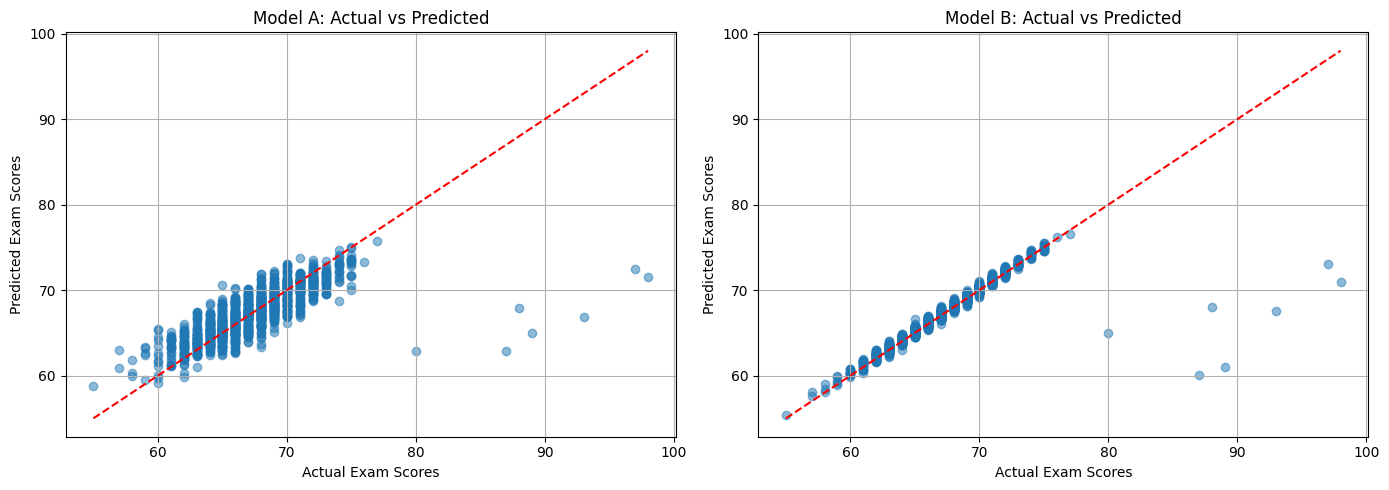

In [16]:
# ==========================================================
# STAGE 13 — VISUALIZE ACTUAL VS PREDICTED SCORES
# Purpose: Compare how closely each model predicts
# the actual examination scores.
# ==========================================================

plt.figure(figsize=(14, 5))

# Model A
plt.subplot(1, 2, 1)
plt.scatter(y_test, pred_A, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Model A: Actual vs Predicted")
plt.grid(True)

# Model B
plt.subplot(1, 2, 2)
plt.scatter(y_test, pred_B, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Model B: Actual vs Predicted")
plt.grid(True)

plt.tight_layout()
plt.show()

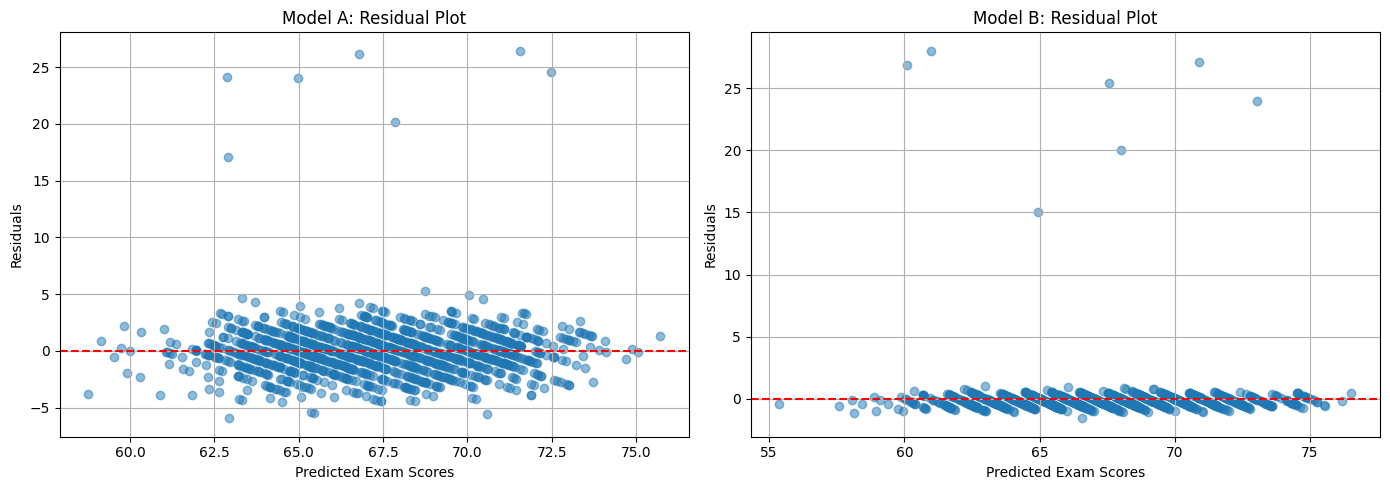

RESIDUAL ANALYSIS COMPLETED
Model A Mean Residual: -0.0123
Model B Mean Residual: -0.0492


In [17]:
# ==========================================================
# STAGE 14 — RESIDUAL ANALYSIS
# Purpose: Examine prediction errors for both models.
# ==========================================================

# Calculate residuals
residuals_A = y_test - pred_A
residuals_B = y_test - pred_B

# Plot residuals for Model A and Model B
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.scatter(pred_A, residuals_A, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Exam Scores")
plt.ylabel("Residuals")
plt.title("Model A: Residual Plot")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(pred_B, residuals_B, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Exam Scores")
plt.ylabel("Residuals")
plt.title("Model B: Residual Plot")
plt.grid(True)

plt.tight_layout()
plt.show()

print("RESIDUAL ANALYSIS COMPLETED")
print("===========================")
print("Model A Mean Residual:", round(residuals_A.mean(), 4))
print("Model B Mean Residual:", round(residuals_B.mean(), 4))

In [18]:
# ==========================================================
# STAGE 15 — FINAL MODEL COMPARISON
# Purpose: Present the final performance of both models.
# ==========================================================

final_comparison = pd.DataFrame({
    "Evaluation Metric": ["R-squared (R2)", "MAE", "MSE", "RMSE"],
    "Model A (2 Predictors)": [r2_A, mae_A, mse_A, rmse_A],
    "Model B (19 Predictors)": [r2_B, mae_B, mse_B, rmse_B]
})

print("FINAL REGRESSION MODEL COMPARISON")
print("=================================")
print(final_comparison.round(4).to_string(index=False))

print("\nBEST MODEL: MODEL B")
print("Reason: Higher R2 and lower MAE, MSE, and RMSE.")

FINAL REGRESSION MODEL COMPARISON
Evaluation Metric  Model A (2 Predictors)  Model B (19 Predictors)
   R-squared (R2)                  0.5890                   0.7696
              MAE                  1.4690                   0.4524
              MSE                  5.8091                   3.2560
             RMSE                  2.4102                   1.8044

BEST MODEL: MODEL B
Reason: Higher R2 and lower MAE, MSE, and RMSE.
